# Plot results of parameter sweeps for Context Identification task with both outputs

The purpose of this notebook is to plot some analyses of the results of a hyperparameter sweep performed on the `ContextIdentification` task when the model was tasked to give both outputs. The parameters were:

1. Seed
2. Gamma
3. Attention mechanism

## Imports

In [1]:
import json
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

import seaborn as sns

## Unsigned models

### Convert JSON to DataFrame

In [2]:
with open("../data/partial_relational_sweep.json", "r") as f:
    results = json.load(f)

In [3]:
rows = []
for attn_kind, d2 in results.items():
    for gamma_str, d3 in d2.items():
        gamma = float(gamma_str)
        for seed_str, hist in d3.items():
            seed = int(seed_str)

            # history lists
            train_acc_f  = np.array(hist["train_acc_f"], dtype=float)
            test_acc_f   = np.array(hist["test_acc_f"], dtype=float)
            train_acc_p  = np.array(hist["train_acc_p"], dtype=float)
            test_acc_p   = np.array(hist["test_acc_p"], dtype=float)

            rows.append({
                "attn_kind": attn_kind,
                "gamma": gamma,
                "seed": seed,

                "epochs": len(train_acc_f),

                "final_train_acc_feature":  train_acc_f[-1],
                "final_test_acc_feature":  test_acc_f[-1],
                "final_train_acc_position":  train_acc_p[-1],
                "final_test_acc_position":  test_acc_p[-1],

                # optional: best epoch metrics
                "best_test_acc_feature":  float(test_acc_f.max()),
                "best_test_acc_position":  float(test_acc_p.max()),
            })

In [4]:
df = pd.DataFrame(rows)
df.head()

,attn_kind,gamma,seed,epochs,final_train_acc_feature,final_test_acc_feature,final_train_acc_position,final_test_acc_position,best_test_acc_feature,best_test_acc_position
0,linear,0.0,0,2500,0.976,0.900,0.158,0.094,0.926,0.126
1,linear,0.0,1,2500,0.982,0.898,0.188,0.088,0.926,0.116
2,linear,0.0,2,2500,0.984,0.868,0.154,0.084,0.896,0.138
3,linear,0.0,3,2500,0.976,0.878,0.168,0.074,0.898,0.114
4,linear,0.0,4,2500,0.974,0.904,0.196,0.130,0.918,0.152


### Test accuracy heatmap

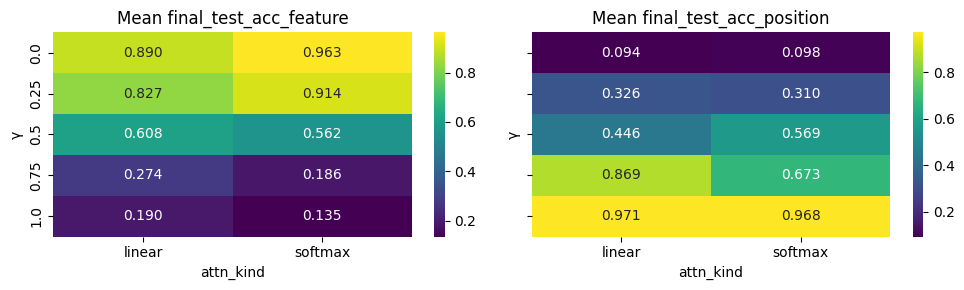

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharey=True)

for ax, acc in zip(axes, ["final_test_acc_feature", "final_test_acc_position"]):
    pivot = (
        df
        .groupby(["gamma", "attn_kind"])[acc]
        .mean()
        .reset_index()
        .pivot(index="gamma", columns="attn_kind", values=acc)
        .sort_index()
    )

    sns.heatmap(pivot, ax=ax, annot=True, fmt=".3f", cmap="viridis")
    ax.set_title(f"Mean {acc}")
    ax.set_xlabel("attn_kind")
    ax.set_ylabel("γ")

plt.tight_layout()
plt.show()

## Signed models

### Convert JSON to DataFrame

In [6]:
with open("../data/partial_relational_sweep_signed.json", "r") as f:
    results = json.load(f)

In [7]:
rows = []
for attn_kind, d2 in results.items():
    for gamma_str, d3 in d2.items():
        gamma = float(gamma_str)
        for seed_str, hist in d3.items():
            seed = int(seed_str)

            # history lists
            train_acc_f  = np.array(hist["train_acc_f"], dtype=float)
            test_acc_f   = np.array(hist["test_acc_f"], dtype=float)
            train_acc_p  = np.array(hist["train_acc_p"], dtype=float)
            test_acc_p   = np.array(hist["test_acc_p"], dtype=float)

            rows.append({
                "attn_kind": attn_kind,
                "gamma": gamma,
                "seed": seed,

                "epochs": len(train_acc_f),

                "final_train_acc_feature":  train_acc_f[-1],
                "final_test_acc_feature":  test_acc_f[-1],
                "final_train_acc_position":  train_acc_p[-1],
                "final_test_acc_position":  test_acc_p[-1],

                # optional: best epoch metrics
                "best_test_acc_feature":  float(test_acc_f.max()),
                "best_test_acc_position":  float(test_acc_p.max()),
            })

In [8]:
df = pd.DataFrame(rows)
df.head()

,attn_kind,gamma,seed,epochs,final_train_acc_feature,final_test_acc_feature,final_train_acc_position,final_test_acc_position,best_test_acc_feature,best_test_acc_position
0,linear,0.0,0,2500,0.952,0.882,0.184,0.086,0.918,0.118
1,linear,0.0,1,2500,0.990,0.890,0.206,0.102,0.914,0.122
2,linear,0.0,2,2500,0.980,0.866,0.182,0.098,0.896,0.140
3,linear,0.0,3,2500,0.980,0.880,0.182,0.076,0.908,0.130
4,linear,0.0,4,2500,0.948,0.858,0.160,0.114,0.882,0.138


### Test accuracy heatmap

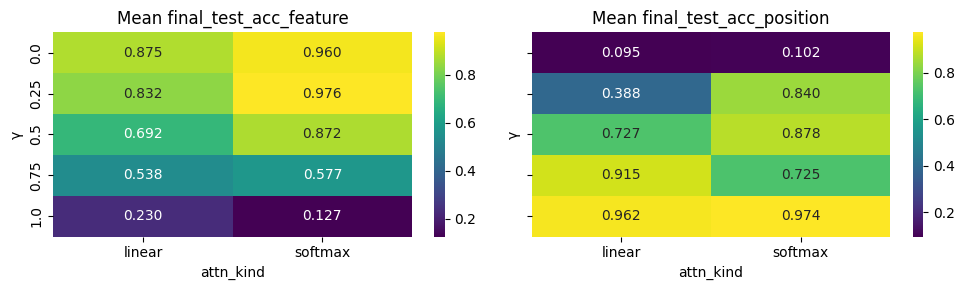

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharey=True)

for ax, acc in zip(axes, ["final_test_acc_feature", "final_test_acc_position"]):
    pivot = (
        df
        .groupby(["gamma", "attn_kind"])[acc]
        .mean()
        .reset_index()
        .pivot(index="gamma", columns="attn_kind", values=acc)
        .sort_index()
    )

    sns.heatmap(pivot, ax=ax, annot=True, fmt=".3f", cmap="viridis")
    ax.set_title(f"Mean {acc}")
    ax.set_xlabel("attn_kind")
    ax.set_ylabel("γ")

plt.tight_layout()
plt.show()